# 01 · Exploratory data analysis

**Project:** Machine Learning Based Algorithmic Trading Signals: A Comparative Study Against Technical Baseline Strategies

This notebook looks at the raw market data before any modelling: coverage, return distributions, autocorrelation
(how predictable daily returns are) and the distribution of the three-class target. All data is loaded through the
same `src.data_loader` used by the pipeline, from the local cache in `data/raw/` (it is downloaded on the first run).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.utils import load_config
cfg = load_config(ROOT / "config.yaml")
RESULTS = ROOT / cfg["experiment"]["results_dir"]

In [2]:
from src.data_loader import load_universe
frames, manifest = load_universe(cfg)
pd.DataFrame(manifest)[["ticker", "source", "is_synthetic", "rows", "first_date", "last_date"]]

07:45:50 | INFO | SPY: 4024 rows 2010-01-04 -> 2025-12-31 (source=cache)


07:45:50 | INFO | AAPL: 4024 rows 2010-01-04 -> 2025-12-31 (source=cache)


07:45:51 | INFO | MSFT: 4024 rows 2010-01-04 -> 2025-12-31 (source=cache)


,ticker,source,is_synthetic,rows,first_date,last_date
0,SPY,cache,False,4024,2010-01-04,2025-12-31
1,AAPL,cache,False,4024,2010-01-04,2025-12-31
2,MSFT,cache,False,4024,2010-01-04,2025-12-31


## Data validation report
Every cleaning action is counted; nothing is imputed.

In [3]:
pd.DataFrame({m["ticker"]: m["validation"] for m in manifest})

,SPY,AAPL,MSFT
input_rows,4024,4024,4024
was_sorted,True,True,True
duplicate_dates_removed,0,0,0
rows_with_missing_prices_removed,0,0,0
rows_with_nonpositive_prices_removed,0,0,0
missing_volume_rows,0,0,0
zero_volume_rows,0,0,0
high_low_inconsistencies_repaired,0,0,0
max_calendar_gap_days,5,5,5
gaps_over_7_days,0,0,0


## Summary statistics of daily close-to-close returns

In [4]:
rows = []
for t, df in frames.items():
    r = df["close"].pct_change().dropna()
    rows.append({"ticker": t, "days": len(r), "mean_daily_%": r.mean() * 100, "std_daily_%": r.std() * 100,
                 "annualised_return_%": ((1 + r).prod() ** (252 / len(r)) - 1) * 100,
                 "annualised_vol_%": r.std() * np.sqrt(252) * 100, "skew": r.skew(), "excess_kurtosis": r.kurt(),
                 "share_up_days_%": (r > 0).mean() * 100})
pd.DataFrame(rows).round(3)

,ticker,days,mean_daily_%,std_daily_%,annualised_return_%,annualised_vol_%,skew,excess_kurtosis,share_up_days_%
0,SPY,4023,0.058,1.084,13.930,17.210,-0.335,12.117,55.406
1,AAPL,4023,0.109,1.775,26.447,28.170,0.066,6.186,53.070
2,MSFT,4023,0.088,1.606,20.978,25.491,0.095,7.771,52.448


## Adjusted price history (log scale)
Shaded regions are the validation and test periods used by the holdout experiment.

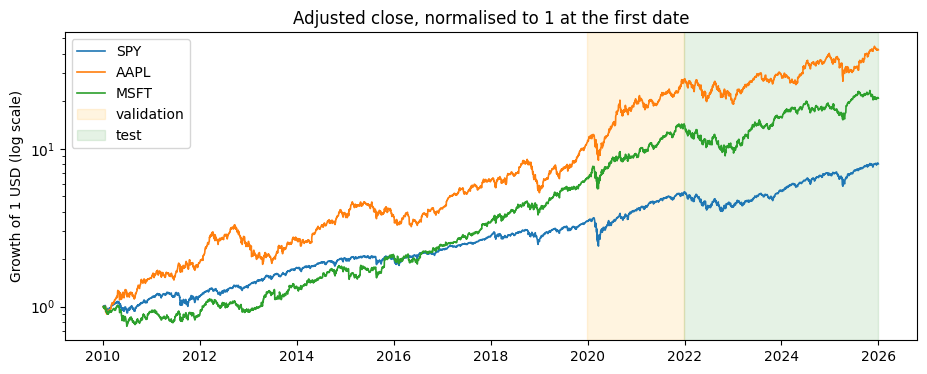

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
for t, df in frames.items():
    ax.plot(df.index, df["close"] / df["close"].iloc[0], label=t, lw=1.2)
ax.set_yscale("log"); ax.set_ylabel("Growth of 1 USD (log scale)")
ax.axvspan(pd.Timestamp(cfg["split"]["train_end"]), pd.Timestamp(cfg["split"]["val_end"]), color="orange", alpha=0.12, label="validation")
ax.axvspan(pd.Timestamp(cfg["split"]["val_end"]), df.index[-1], color="green", alpha=0.10, label="test")
ax.legend(); ax.set_title("Adjusted close, normalised to 1 at the first date"); plt.show()

## Return distribution
Daily returns have fatter tails (higher kurtosis) than a normal distribution with the same variance.

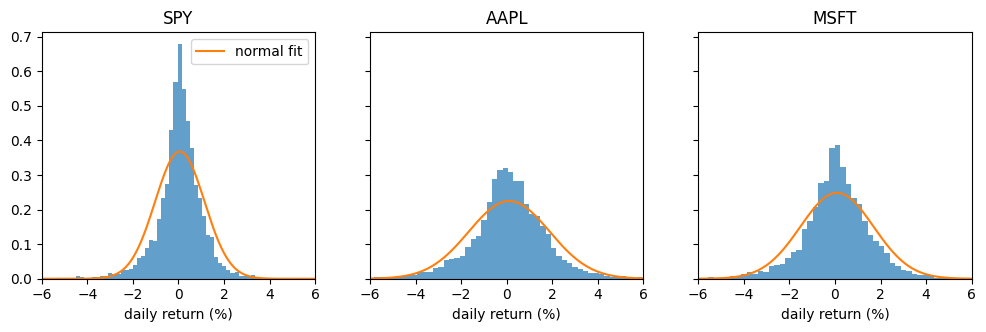

In [6]:
fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 3.2), sharey=True)
for ax, (t, df) in zip(np.atleast_1d(axes), frames.items()):
    r = df["close"].pct_change().dropna() * 100
    ax.hist(r, bins=120, density=True, alpha=0.7)
    x = np.linspace(-6, 6, 300)
    ax.plot(x, np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi)), lw=1.5, label="normal fit")
    ax.set_xlim(-6, 6); ax.set_title(t); ax.set_xlabel("daily return (%)")
np.atleast_1d(axes)[0].legend(); plt.show()

## Autocorrelation: how predictable are daily returns?
Near-zero autocorrelation of returns means past returns carry little *linear* information about the next day's
return, so low classification accuracy should be expected. Absolute returns, by contrast, are usually positively
autocorrelated (volatility clustering), so volatility features carry information about *risk* even when they say little about direction.

In [7]:
lags = range(1, 11)
ac = {}
for t, df in frames.items():
    r = df["close"].pct_change().dropna()
    ac[(t, "returns")] = [r.autocorr(l) for l in lags]
    ac[(t, "|returns|")] = [r.abs().autocorr(l) for l in lags]
pd.DataFrame(ac, index=pd.Index(lags, name="lag")).round(3)

SPY              AAPL              MSFT          
    returns |returns| returns |returns| returns |returns|
lag                                                      
1    -0.104     0.311  -0.034     0.196  -0.100     0.225
2     0.062     0.372   0.010     0.150   0.002     0.206
3    -0.042     0.332  -0.034     0.161  -0.014     0.160
4    -0.046     0.327  -0.005     0.148  -0.028     0.184
5    -0.004     0.290  -0.002     0.149  -0.002     0.158
6    -0.068     0.297  -0.021     0.144  -0.058     0.167
7     0.089     0.263   0.037     0.121   0.048     0.147
8    -0.078     0.281  -0.075     0.158  -0.081     0.141
9     0.078     0.260   0.054     0.133   0.065     0.134
10   -0.016     0.256  -0.016     0.113  -0.015     0.162

## Target class distribution (full sample)
The neutral band is ±`neutral_threshold` around zero (configurable in `config.yaml`).

In [8]:
from src.targets import build_target_frame, class_distribution
out = []
for t, df in frames.items():
    tg = build_target_frame(df, cfg["target"], cfg["execution"]["convention"])
    d = class_distribution(tg["label"], cfg["target"]["scheme"]); d.insert(0, "ticker", t); out.append(d)
pd.concat(out).pivot(index="ticker", columns="class", values="frequency").round(3)

class,Down,Neutral,Up
ticker,,,
AAPL,0.428,0.060,0.513
MSFT,0.434,0.067,0.499
SPY,0.382,0.112,0.506
